# 05 — Personalización (LOSO)

**Objetivo.** Medir cuánto gana un paciente **nuevo** cuando el modelo global se adapta con sus
primeros N ∈ {1, 3, 7} días, en *leave-one-subject-out*, y compararlo con entrenar solo con esos
días y con no adaptar. Es el experimento que sostiene la contribución del TFM.

**Entradas.** `experiments/results/<exp_id>/metrics.json` de:
- `20260928-loso-global`, `-individual`, `-ft` y `-ft-ponderada` (los cuatro regímenes), que
  reutilizan los 36 backbones de `20260928-loso-backbones`;
- `20260928-global-bigru-alpha-val` (corrección de la Fase 4);
- `20260930-loso-ft-rmse` y `20260930-loso-ft-ponderada-rmse` (análisis de sensibilidad
  post hoc, sección 7).


**Protocolo.** Para cada paciente excluido `p` y semilla: backbone entrenado con los otros 11;
adaptación con los primeros N días de `p`; receta y umbral α elegidos en el **desarrollo** (su
train desde el día 7 + 60 min) de **los otros pliegues**; test oficial de `p` puntuado una sola
vez. Tolerancia de 15 min, 61 eventos puntuables, presupuesto de 1 falsa alarma/día. El recall se
promedia por evento entre las 3 semillas y lleva un IC95 % bootstrap sobre los eventos.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from tfm.eval.compare import (adaptation_curve_frame, load_result, loso_patient_table,
                              personalization_tests, reference_lines)
from tfm.viz import FIG_WIDTH_FULL
from tfm.viz.plots import (REGIME_LABELS, REGIME_STYLES, plot_adaptation_curves, save_figure,
                           set_style)

set_style()
pd.set_option("display.width", 150)

EXP = {"global": "20260928-loso-global", "individual": "20260928-loso-individual",
       "ft": "20260928-loso-ft", "ft_weighted": "20260928-loso-ft-ponderada"}
ALPHA_VAL = "20260928-global-bigru-alpha-val"
results = {regime: load_result(exp) for regime, exp in EXP.items()}
alpha_val = load_result(ALPHA_VAL)

## 1. La cifra de la Fase 4, sin fuga

En la Fase 4 el umbral α se eligió sobre el test oficial. Aquí se elige en el corte de
validación (20 % final del train de cada paciente) y solo después se aplica al test. Ese corte ya
se usó para la parada temprana, así que la cifra es todavía algo optimista, pero el test no
interviene en ninguna decisión.

In [2]:
filas = []
for h, por_presupuesto in alpha_val["aggregate"].items():
    for presupuesto, a in por_presupuesto.items():
        r = a["recall"]
        filas.append({"PH": int(h), "FA/día máx.": float(presupuesto),
                      "α por semilla": a["alpha_by_seed"],
                      "recall": r["point"], "IC95 %": f"[{r['lo']:.3f}–{r['hi']:.3f}]", "n": r["n"],
                      "FA/día test": sum(a["false_alarms_per_day_by_seed"]) / len(a["false_alarms_per_day_by_seed"]),
                      "dentro del presupuesto en val": a["within_budget_by_seed"]})
pd.DataFrame(filas).round(3)

,PH,FA/día máx.,α por semilla,recall,IC95 %,n,FA/día test,dentro del presupuesto en val
0,30,0.5,"[0.5, 0.5, 0.5]",0.186,[0.109–0.268],61,0.356,"[True, True, True]"
1,30,1.0,"[0.3, 0.4, 0.4]",0.574,[0.475–0.672],61,0.780,"[True, True, True]"
2,30,2.0,"[0.2, 0.2, 0.2]",0.962,[0.912–1.000],61,1.593,"[True, True, True]"
3,60,0.5,"[0.5, 0.4, 0.6]",0.027,[0.000–0.066],61,0.254,"[True, True, True]"
4,60,1.0,"[0.4, 0.4, 0.4]",0.071,[0.016–0.137],61,0.443,"[True, True, True]"
5,60,2.0,"[0.25, 0.25, 0.2]",0.399,[0.290–0.503],61,1.614,"[True, True, True]"


## 2. Rendimiento frente a días de adaptación

La figura del TFM. Arriba, recall por eventos con la alarma `P(y<70) > α` bajo 1 falsa
alarma/día; abajo, RMSE. El día 0 es el global-11 sin adaptar. Las horizontales son las
referencias: el global-12 de la Fase 4 (con α en validación) y el LSTM por paciente entrenado con
todo su train, este último solo en el panel de RMSE porque no emite probabilidad.

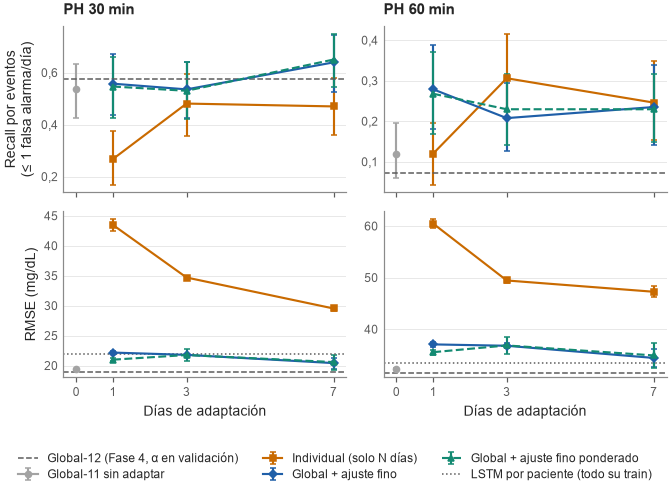

In [3]:
frame = adaptation_curve_frame(results)
refs = reference_lines(alpha_val, load_result("20260916-global-bigru"),
                       load_result("20260916-baseline-lstm-paciente"))
fig = plot_adaptation_curves(frame, refs)
save_figure(fig, "05_adaptacion_dias")
plt.show()

Con 1 y 3 días, el ajuste fino («Global + ajuste fino» y su versión ponderada) no mejora el recall
a 30 min del global-11 sin adaptar (0,536) y **empeora su RMSE** (19,40 → 20,98–22,16 mg/dL). El
individual queda muy por encima en error con cualquier N (43,45 → 29,52 mg/dL a 30 min), peor
incluso que el LSTM por paciente entrenado con todo su train (línea de puntos). A 60 min el ajuste
fino sube el recall (0,120 → 0,21–0,28), con IC que se solapan con el del global y a cambio de
2–5 mg/dL de RMSE; esa subida desaparece a igual presupuesto de falsas alarmas (sección 8).

## 3. Los cuatro regímenes

Media entre semillas; el recall es el promediado por evento con su IC95 %.

In [4]:
tabla = frame.assign(
    regimen=frame["regime"].map(REGIME_LABELS),
    recall_IC=frame.apply(lambda r: f"{r.recall:.3f} [{r.recall_lo:.3f}–{r.recall_hi:.3f}]", axis=1),
    RMSE=frame.apply(lambda r: f"{r.rmse_mean:.2f} ± {r.rmse_std:.2f}", axis=1),
)[["regimen", "n_days", "horizon_min", "recall_IC", "false_alarms_per_day", "RMSE"]]
tabla.sort_values(["horizon_min", "regimen", "n_days"]).round(3)

,regimen,n_days,horizon_min,recall_IC,false_alarms_per_day,RMSE
8,Global + ajuste fino,1,30,0.557 [0.437–0.672],0.839,22.16 ± 0.18
10,Global + ajuste fino,3,30,0.536 [0.426–0.639],0.826,21.78 ± 0.12
12,Global + ajuste fino,7,30,0.639 [0.525–0.743],0.939,20.40 ± 0.91
14,Global + ajuste fino ponderado,1,30,0.546 [0.426–0.661],0.775,20.98 ± 0.27
16,Global + ajuste fino ponderado,3,30,0.530 [0.421–0.639],0.939,21.75 ± 0.98
18,Global + ajuste fino ponderado,7,30,0.650 [0.546–0.749],0.861,20.57 ± 1.25
0,Global-11 sin adaptar,0,30,0.536 [0.426–0.634],0.667,19.40 ± 0.04
2,Individual (solo N días),1,30,0.268 [0.169–0.377],0.696,43.45 ± 1.00
4,Individual (solo N días),3,30,0.481 [0.355–0.596],0.920,34.69 ± 0.18
6,Individual (solo N días),7,30,0.470 [0.361–0.579],0.799,29.52 ± 0.47


## 4. Paciente a paciente

Con 12 pacientes la media esconde el resultado. RMSE y recall de la alarma por paciente con 7
días de adaptación a 30 min, con el número de eventos de test al lado: el recall de un paciente
con uno o dos eventos no se interpreta.

In [5]:
por_paciente = pd.concat(
    {REGIME_LABELS[r]: loso_patient_table(results[r], 0 if r == "global" else 7, 30).set_index("patient")
     for r in EXP}, axis=1)
por_paciente.round(3)

Global-11 sin adaptar                       Individual (solo N días)                       Global + ajuste fino                        \
                         rmse alarm_recall n_events                     rmse alarm_recall n_events                 rmse alarm_recall n_events   
patient                                                                                                                                         
540                    21.575        0.848       11                   32.680        0.818       11               21.474        1.000       11   
544                    17.494        0.333        2                   21.712        0.167        2               17.450        0.667        2   
552                    16.429        0.238        7                   25.978        0.143        7               16.033        0.857        7   
559                    18.685        0.667        3                   27.979        0.444        3               18.779        0.667        3   
563                    18.711        0.500        2                   25.307        0.333        2               19.971        0.333        2   
567                    20.869        0.533        5                   24.739        0.533        5               19.865        0.800        5   
570                    17.546        0.167        2                   28.003        0.667        2               17.505        0.500        2   
575                    21.812        0.708        8                   30.521        0.625        8               22.679        0.958        8   
584                    23.101        0.167        2                   29.882        0.500        2               23.991        0.500        2   
588                    17.884        1.000        1                   32.318        0.000        1               23.923        0.333        1   
591                    20.916        0.424       11                   30.266        0.212       11               22.434        0.212       11   
596                    16.246        0.476        7                   38.834        0.571        7               17.618        0.238        7   

        Global + ajuste fino ponderado                        
                                  rmse alarm_recall n_events  
patient                                                       
540                             21.606        1.000       11  
544                             17.264        0.667        2  
552                             16.564        0.762        7  
559                             20.499        0.556        3  
563                             20.074        0.833        2  
567                             20.796        0.800        5  
570                             16.821        0.500        2  
575                             23.147        0.958        8  
584                             22.670        0.333        2  
588                             24.797        0.000        1  
591                             22.557        0.273       11  
596                             17.113        0.333        7

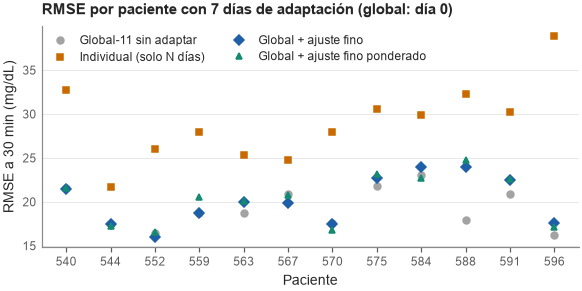

In [6]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH_FULL, 2.6))
for r in EXP:
    t = loso_patient_table(results[r], 0 if r == "global" else 7, 30)
    st = REGIME_STYLES[r]
    ax.plot(t["patient"], t["rmse"], marker=st["marker"], color=st["color"], ms=4.5, ls="",
            label=REGIME_LABELS[r])
ax.set_xlabel("Paciente")
ax.set_ylabel("RMSE a 30 min (mg/dL)")
ax.set_title("RMSE por paciente con 7 días de adaptación (global: día 0)")
ax.legend(ncol=2)
save_figure(fig, "05_rmse_por_paciente")
plt.show()

Con 7 días, el individual es el peor en los 12 pacientes. El ajuste fino queda cerca del global
en la mayoría, pero empeora con claridad en 588 (17,88 → 23,92 mg/dL) y en 591 (20,92 → 22,43).
Las mejoras son pequeñas: la mayor es la de 567 (20,87 → 19,87 mg/dL).

## 5. Wilcoxon pareado por paciente

Tres comparaciones (ajuste fino frente a no adaptar, ponderado frente a no ponderado, ajuste fino
frente a individual) para cada N, horizonte y métrica. Holm corrige dentro de cada familia
(métrica × horizonte, 9 tests). En el recall se excluyen los pacientes sin eventos de test.

In [7]:
pruebas = personalization_tests(results)
pruebas[["comparison", "n_days", "horizon_min", "metric", "n", "median_diff", "p_value", "p_holm"]].round(4)

,comparison,n_days,horizon_min,metric,n,median_diff,p_value,p_holm
0,ft vs global,1,30,rmse,12,2.3751,0.0005,0.0044
1,ft vs global,1,30,alarm_recall,12,0.0000,0.8672,1.0000
2,ft vs global,1,60,rmse,12,3.2395,0.0005,0.0044
3,ft vs global,1,60,alarm_recall,12,0.0606,0.0469,0.3281
4,ft vs global,3,30,rmse,12,1.9823,0.0005,0.0044
5,ft vs global,3,30,alarm_recall,12,0.0606,0.8975,1.0000
6,ft vs global,3,60,rmse,12,4.8180,0.0049,0.0244
7,ft vs global,3,60,alarm_recall,12,0.0152,0.1562,0.7852
8,ft vs global,7,30,rmse,12,0.4807,0.1514,0.4541
9,ft vs global,7,30,alarm_recall,12,0.2008,0.2686,1.0000


Tras Holm, el ajuste fino es **significativamente peor** que no adaptar en RMSE con 1 y 3 días
(p_Holm 0,004 en ambos horizontes, 0,024 a 60 min con 3 días), y no difiere con 7 días. En
recall no hay ninguna diferencia significativa entre regímenes. Ponderar la pérdida no cambia
nada frente al ajuste sin ponderar. El individual es significativamente peor en RMSE que el
ajuste fino en todos los casos (p_Holm 0,004).

## 6. Qué recetas se eligieron

La receta y α de cada pliegue se eligen con los otros 11. Si casi siempre sale la misma, la
elección es estable; si cambia mucho entre pliegues, lo es menos.

In [8]:
elegidas = pd.DataFrame([
    {"regimen": REGIME_LABELS[r], "n_dias": int(n), "semilla": s, "paciente": p,
     "receta": c["recipe"], "alpha_30": c["alpha"]["30"], "alpha_60": c["alpha"]["60"],
     "en_presupuesto": all(c["within_budget"].values())}
    for r, res in results.items() for n, block in res["by_days"].items()
    for s, sel in block["selection"].items() for p, c in sel.items()])
print("pliegues fuera del presupuesto en desarrollo:", int((~elegidas["en_presupuesto"]).sum()))
elegidas.groupby(["regimen", "n_dias"])["receta"].value_counts().rename("veces")

pliegues fuera del presupuesto en desarrollo: 0


regimen                   n_dias  receta                              
Global + ajuste fino      1       layers=all|lr=0.0001|lam=0|epochs=40     7
                                  layers=all|lr=0.0001|lam=0|epochs=5      6
                                  layers=head|lr=0.001|lam=0|epochs=40     6
                                  layers=head|lr=0.001|lam=0|epochs=20     4
                                  layers=head|lr=0.001|lam=0|epochs=10     3
                                                                          ..
Individual (solo N días)  3       layers=all|lr=0.001|lam=0|epochs=50      1
                          7       layers=all|lr=0.001|lam=0|epochs=25     30
                                  layers=all|lr=0.003|lam=0|epochs=25      4
                                  layers=all|lr=0.001|lam=0|epochs=50      1
                                  layers=all|lr=0.003|lam=0|epochs=50      1
Name: veces, Length: 88, dtype: int64

## 7. Análisis de sensibilidad post hoc: selección con restricción de RMSE

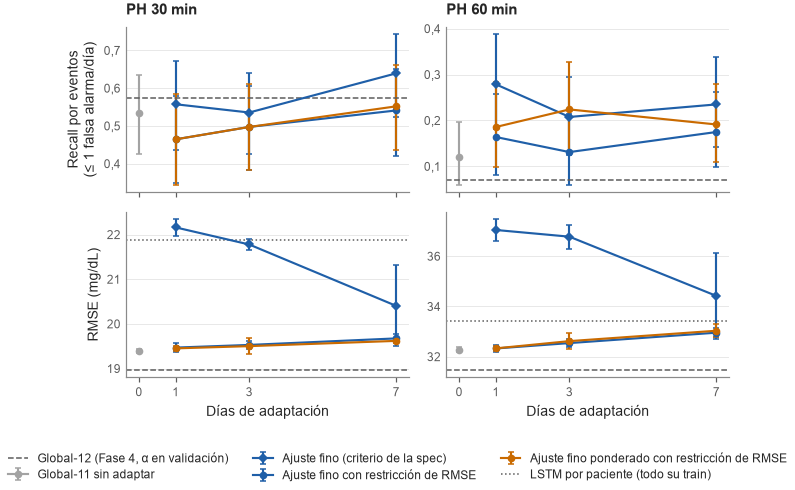

In [9]:
EXP_RMSE = {"ft_rmse": "20260930-loso-ft-rmse", "ft_weighted_rmse": "20260930-loso-ft-ponderada-rmse"}
LABELS_RMSE = {"global": REGIME_LABELS["global"],
               "ft": "Ajuste fino (criterio de la spec)",
               "ft_rmse": "Ajuste fino con restricción de RMSE",
               "ft_weighted_rmse": "Ajuste fino ponderado con restricción de RMSE"}
sens = {"global": results["global"], "ft": results["ft"],
        **{r: load_result(e) for r, e in EXP_RMSE.items()}}
frame_rmse = adaptation_curve_frame(sens)
fig = plot_adaptation_curves(frame_rmse, refs, labels=LABELS_RMSE)
save_figure(fig, "05_adaptacion_dias_rmse")
plt.show()

Con la restricción de RMSE (las dos series «con restricción de RMSE»), el error queda al nivel del
global (19,45–19,67 a 30 min) y el recall también: 0,464–0,552 frente a 0,536 a 30 min. A 60 min
sube algo (0,13–0,22 frente a 0,120), con IC solapados. La ganancia de recall del criterio de la
spec («Ajuste fino (criterio de la spec)») solo aparece cuando el modelo empeora y avisa más.

In [10]:
tabla_rmse = frame_rmse.assign(
    regimen=frame_rmse["regime"].map(LABELS_RMSE),
    recall_IC=frame_rmse.apply(lambda r: f"{r.recall:.3f} [{r.recall_lo:.3f}–{r.recall_hi:.3f}]", axis=1),
    RMSE=frame_rmse.apply(lambda r: f"{r.rmse_mean:.2f} ± {r.rmse_std:.2f}", axis=1),
)[["regimen", "n_days", "horizon_min", "recall_IC", "false_alarms_per_day", "RMSE"]]
tabla_rmse.sort_values(["horizon_min", "regimen", "n_days"]).round(3)

,regimen,n_days,horizon_min,recall_IC,false_alarms_per_day,RMSE
2,Ajuste fino (criterio de la spec),1,30,0.557 [0.437–0.672],0.839,22.16 ± 0.18
4,Ajuste fino (criterio de la spec),3,30,0.536 [0.426–0.639],0.826,21.78 ± 0.12
6,Ajuste fino (criterio de la spec),7,30,0.639 [0.525–0.743],0.939,20.40 ± 0.91
8,Ajuste fino con restricción de RMSE,1,30,0.464 [0.350–0.579],0.683,19.47 ± 0.10
10,Ajuste fino con restricción de RMSE,3,30,0.497 [0.383–0.607],0.791,19.53 ± 0.09
12,Ajuste fino con restricción de RMSE,7,30,0.541 [0.421–0.650],0.748,19.67 ± 0.10
14,Ajuste fino ponderado con restricción de RMSE,1,30,0.464 [0.344–0.585],0.704,19.45 ± 0.05
16,Ajuste fino ponderado con restricción de RMSE,3,30,0.497 [0.383–0.612],0.780,19.50 ± 0.18
18,Ajuste fino ponderado con restricción de RMSE,7,30,0.552 [0.437–0.661],0.777,19.62 ± 0.04
0,Global-11 sin adaptar,0,30,0.536 [0.426–0.634],0.667,19.40 ± 0.04


La regla `μ < 70` (sin probabilidad) es la que más cambia con la pérdida ponderada: recall por
eventos medio entre semillas.

In [11]:
mu_rule = pd.DataFrame([
    {"regimen": LABELS_RMSE.get(r, REGIME_LABELS.get(r)), "n_dias": int(n), "PH": int(h),
     "recall_mu70": sum(b["by_seed"][s][h]["summary"]["pooled_event_recall"]["point"]
                        for s in b["by_seed"]) / len(b["by_seed"])}
    for r, res in {**sens, "ft_weighted": results["ft_weighted"]}.items()
    for n, b in res["by_days"].items() for h in ("30", "60")])
mu_rule.pivot_table(index=["regimen", "n_dias"], columns="PH", values="recall_mu70").round(3)

PH                                                       30     60
regimen                                       n_dias              
Ajuste fino (criterio de la spec)             1       0.197  0.109
                                              3       0.180  0.104
                                              7       0.219  0.071
Ajuste fino con restricción de RMSE           1       0.164  0.022
                                              3       0.169  0.038
                                              7       0.175  0.049
Ajuste fino ponderado con restricción de RMSE 1       0.230  0.038
                                              3       0.257  0.098
                                              7       0.317  0.126
Global + ajuste fino ponderado                1       0.279  0.164
                                              3       0.268  0.153
                                              7       0.361  0.142
Global-11 sin adaptar                         0       0.137  0.011

Wilcoxon pareado por paciente para las variantes con restricción, con Holm dentro de cada
familia (métrica × horizonte).

In [12]:
pruebas_rmse = personalization_tests(
    sens, comparisons=(("ft_rmse", "global"), ("ft_weighted_rmse", "global"),
                       ("ft_weighted_rmse", "ft_rmse")))
pruebas_rmse[["comparison", "n_days", "horizon_min", "metric", "n", "median_diff", "p_value", "p_holm"]].round(4)

,comparison,n_days,horizon_min,metric,n,median_diff,p_value,p_holm
0,ft_rmse vs global,1,30,rmse,12,0.0638,0.5186,1.0000
1,ft_rmse vs global,1,30,alarm_recall,12,-0.1310,0.0371,0.3340
2,ft_rmse vs global,1,60,rmse,12,0.0186,0.9097,1.0000
3,ft_rmse vs global,1,60,alarm_recall,12,0.0000,0.1562,0.7812
4,ft_rmse vs global,3,30,rmse,12,0.1902,0.5186,1.0000
5,ft_rmse vs global,3,30,alarm_recall,12,-0.0714,0.2139,1.0000
6,ft_rmse vs global,3,60,rmse,12,0.1274,0.6221,1.0000
7,ft_rmse vs global,3,60,alarm_recall,12,0.0000,0.4688,0.8750
8,ft_rmse vs global,7,30,rmse,12,-0.1111,0.8501,1.0000
9,ft_rmse vs global,7,30,alarm_recall,12,-0.0833,0.8467,1.0000


Una sola diferencia sobrevive a Holm: el ajuste fino ponderado con restricción mejora el recall
a 60 min con 3 días frente al global (mediana +0,127 por paciente, p_Holm 0,035). Es aislada (no
se repite con 1 ni con 7 días) y procede de un análisis post hoc, así que se reporta como indicio,
no como resultado.

## 8. Comprobación a igual presupuesto de falsas alarmas

La selección anidada deja a cada régimen dentro de 1 FA/día en desarrollo, pero en el test cada uno
acaba en un punto distinto, y un recall con más avisos no es una mejor detección. Esta comprobación
se añadió el 2026-10-02, después de verlo en HUPA-UCM (notebook 09). Cada régimen se lee con **su
propio α, el que más detecta sin pasar de 1 FA/día en el test** (`tfm.eval.alarm.recall_at_budget`,
rejilla de α en pasos de 0,02). Es una lectura descriptiva, porque el α sale del test, pero trata
igual a todos los regímenes. No sustituye al resultado principal: lo comprueba.

In [13]:
from tfm.eval.alarm import recall_at_budget, regime_predictions
from tfm.eval.protocol import scorable_events

EXP_ALL = {**EXP, **EXP_RMSE}
events_fn = lambda patient, p: scorable_events(patient, p, "test")  # noqa: E731
rows = []
for regime, exp in EXP_ALL.items():
    res = load_result(exp)
    matched = recall_at_budget(regime_predictions(exp), events_fn, budget=1.0)
    assert matched["within_budget"].all()
    for m in matched.itertuples():
        alarm = res["by_days"][str(m.n_days)]["alarm"][str(m.horizon_min)]
        rows.append({"regimen": regime, "n_dias": m.n_days, "PH": m.horizon_min,
                     "recall_spec": alarm["recall"]["point"],
                     "fa_dia_spec": sum(alarm["false_alarms_per_day_by_seed"]) / len(alarm["false_alarms_per_day_by_seed"]),
                     "recall_1FA": m.recall, "IC_lo": m.recall_lo, "IC_hi": m.recall_hi,
                     "fa_dia_1FA": m.false_alarms_per_day, "alpha_test": m.alpha, "eventos": m.n_events})
igual_presupuesto = pd.DataFrame(rows).sort_values(["PH", "n_dias", "regimen"])
igual_presupuesto.set_index(["PH", "regimen", "n_dias"]).round(3)

recall_spec  fa_dia_spec  recall_1FA  IC_lo  IC_hi  fa_dia_1FA  alpha_test  eventos
PH regimen          n_dias                                                                                     
30 global           0             0.536        0.667       0.781  0.694  0.863       0.956        0.28       61
   ft               1             0.557        0.839       0.650  0.541  0.765       0.942        0.20       61
   ft_rmse          1             0.464        0.683       0.732  0.628  0.825       0.958        0.26       61
   ft_weighted      1             0.546        0.775       0.683  0.574  0.792       0.985        0.22       61
   ft_weighted_rmse 1             0.464        0.704       0.716  0.607  0.814       0.980        0.28       61
   individual       1             0.268        0.696       0.311  0.208  0.426       0.934        0.02       61
   ft               3             0.536        0.826       0.607  0.503  0.710       0.972        0.20       61
   ft_rmse          3             0.497        0.791       0.667  0.563  0.765       0.947        0.28       61
   ft_weighted      3             0.530        0.939       0.689  0.590  0.781       0.991        0.26       61
   ft_weighted_rmse 3             0.497        0.780       0.656  0.546  0.765       0.983        0.32       61
   individual       3             0.481        0.920       0.508  0.393  0.629       0.972        0.10       61
   ft               7             0.639        0.939       0.672  0.563  0.776       0.929        0.28       61
   ft_rmse          7             0.541        0.748       0.683  0.579  0.781       0.920        0.28       61
   ft_weighted      7             0.650        0.861       0.754  0.656  0.842       0.942        0.32       61
   ft_weighted_rmse 7             0.552        0.777       0.650  0.536  0.765       0.910        0.34       61
   individual       7             0.470        0.799       0.519  0.421  0.623       0.899        0.14       61
60 global           0             0.120        0.502       0.262  0.158  0.366       0.958        0.30       61
   ft               1             0.279        0.812       0.301  0.197  0.410       0.999        0.28       61
   ft_rmse          1             0.164        0.464       0.290  0.180  0.399       0.993        0.30       61
   ft_weighted      1             0.268        0.823       0.268  0.169  0.366       0.821        0.38       61
   ft_weighted_rmse 1             0.186        0.507       0.273  0.164  0.377       0.896        0.32       61
   individual       1             0.120        0.821       0.137  0.060  0.230       0.942        0.08       61
   ft               3             0.208        0.802       0.262  0.175  0.361       0.972        0.26       61
   ft_rmse          3             0.131        0.507       0.262  0.158  0.366       0.985        0.30       61
   ft_weighted      3             0.230        0.931       0.240  0.153  0.333       0.926        0.36       61
   ft_weighted_rmse 3             0.224        0.704       0.257  0.158  0.355       0.934        0.36       61
   individual       3             0.306        1.004       0.284  0.180  0.393       0.972        0.20       61
   ft               7             0.235        0.939       0.230  0.142  0.333       0.926        0.30       61
   ft_rmse          7             0.175        0.607       0.240  0.148  0.339       0.861        0.30       61
   ft_weighted      7             0.230        0.750       0.246  0.164  0.339       0.929        0.40       61
   ft_weighted_rmse 7             0.191        0.583       0.273  0.175  0.377       0.929        0.36       61
   individual       7             0.246        0.985       0.246  0.153  0.344       0.907        0.26       61

**El resultado negativo sale reforzado.** Con la selección anidada, el global sin adaptar trabaja a
0,67 FA/día a 30 min y 0,50 a 60, mientras que los ajustes finos lo hacen a 0,77–0,94 y 0,75–0,94. A
igual presupuesto, el global detecta **0,781 (0,694–0,863)** a 30 min y **ningún régimen adaptado lo
alcanza** (0,607–0,754; el individual, 0,311–0,519).

## Conclusiones

- **La cifra de la Fase 4, sin fuga.** Con α elegido en validación y 1 falsa alarma/día, el
  global-12 detecta 0,574 (IC95 % 0,475–0,672) de los eventos a 30 min y 0,071 (0,016–0,137) a
  60 min. Sustituye al 0,699 / 0,279 anterior, cuyo α se eligió sobre el test.
- **No ver al paciente cuesta poco.** El global-11 sin adaptar obtiene RMSE 19,40 / 32,28 y
  recall 0,536 / 0,120, frente a 18,97 / 31,48 y 0,574 / 0,071 del global-12.
- **Entrenar solo con el paciente nuevo es el peor enfoque.** Con 1 a 7 días el individual
  tiene un RMSE de 43,45 a 29,52 mg/dL a 30 min, significativamente peor que el ajuste fino en
  todos los casos. El resultado más sólido de la fase es que hay que partir de otros pacientes.
- **La hipótesis de personalización no se confirma con ≤ 7 días.** Con el criterio fijado en la
  spec, el ajuste fino empeora el RMSE (significativo con 1 y 3 días) sin mejorar el recall de
  forma significativa, y la pérdida ponderada no cambia esto. Con la restricción de RMSE (post
  hoc) el ajuste fino iguala al global en error y en detección.